<a href="https://colab.research.google.com/github/ramtekeanurag42-max/ramtekeanurag42-max.github.io/blob/main/Student_Score_Prediction_ML_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Student Performance Dataset

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors.csv
Dataset loaded successfully!
Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
# Explore Dataset Information

print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence             

In [4]:
# Select Input Feature and Target Variable

X = df[['Hours_Studied']]
y = df['Exam_Score']

print("Input Feature: Hours_Studied")
print("Target Variable: Exam_Score")

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature: Hours_Studied
Target Variable: Exam_Score
Input Shape: (6607, 1)
Target Shape: (6607,)


In [5]:
# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dataset Split Successfully!")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Dataset Split Successfully!
Training Records: 5285
Testing Records: 1322


In [6]:
# Create Four Machine Learning Models

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "KNN Regression": KNeighborsRegressor(n_neighbors=3)
}

print("Four Machine Learning Models Created Successfully!")

for name in models:
    print(name)

Four Machine Learning Models Created Successfully!
Linear Regression
Decision Tree
Random Forest
KNN Regression


In [7]:
# Train and Evaluate Four Models

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "R2 Score": round(r2, 3)
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
print(results_df)

Model Evaluation Results:
               Model   MAE  R2 Score
0  Linear Regression  2.45     0.232
1      Decision Tree  2.48     0.217
2      Random Forest  2.48     0.219
3     KNN Regression  2.65     0.118


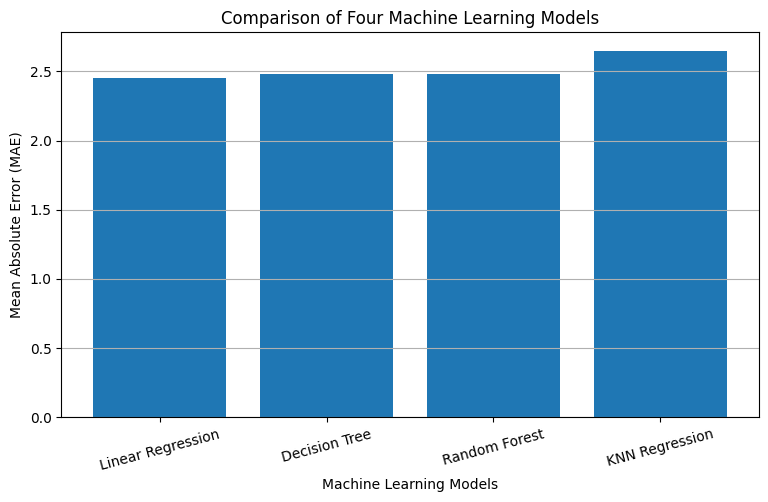

In [8]:
# Compare Model Performance Using MAE

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["MAE"])

plt.title("Comparison of Four Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error (MAE)")

plt.xticks(rotation=15)
plt.grid(axis="y")

plt.show()

In [9]:
# Select the Best Model

best_name = results_df.loc[results_df["MAE"].idxmin(), "Model"]
best_model = models[best_name]

print("Best Model:", best_name)
print("MAE:", results_df.loc[results_df["MAE"].idxmin(), "MAE"])

Best Model: Linear Regression
MAE: 2.45


In [10]:
# Student Score Prediction

hours = float(input("Enter study hours: "))

new_student = pd.DataFrame({
    "Hours_Studied": [hours]
})

predicted_score = best_model.predict(new_student)[0]

predicted_score = max(0, min(100, predicted_score))

print("Selected Model:", best_name)
print("Study Hours:", hours)
print("Predicted Exam Score:", round(predicted_score, 2))

Enter study hours: 5
Selected Model: Linear Regression
Study Hours: 5.0
Predicted Exam Score: 62.94


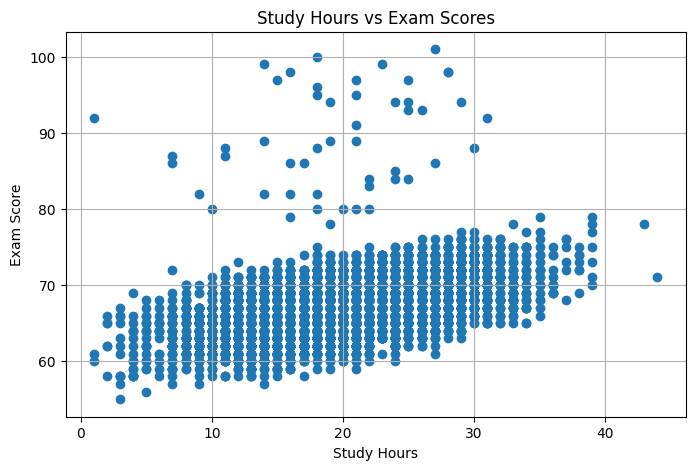

In [11]:
# Visualization of Study Hours vs Exam Scores

plt.figure(figsize=(8, 5))

plt.scatter(df['Hours_Studied'], df['Exam_Score'])

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.grid(True)

plt.show()

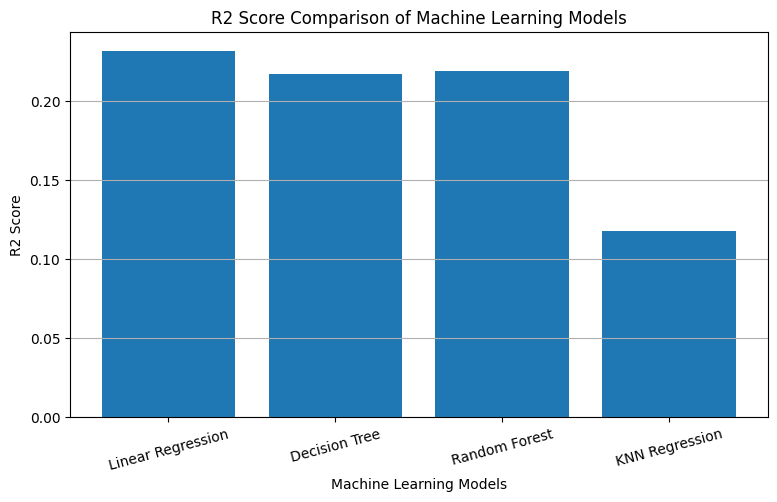

In [12]:
# Compare R2 Scores of Four Models

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["R2 Score"])

plt.title("R2 Score Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=15)
plt.grid(axis="y")

plt.show()

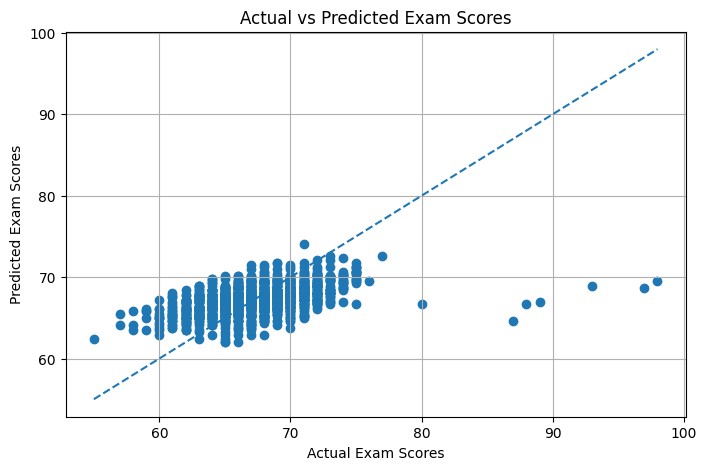

In [13]:
# Actual vs Predicted Exam Scores

predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.grid(True)

plt.show()